In [1]:
from pathlib import Path
import pandas as pd
import nibabel as nib
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score
import numpy as np
import pickle
import random
import SimpleITK as sitk
import cv2
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
import numpy as np
from torchvision import transforms
import mysql.connector
import os
import matplotlib.pyplot as plt

In [2]:
res_size = (96, 48, 128)

base_folder = Path(r"/home/varhai/PRIMUS/data/83_IMPC_DATA/Bioimaging/SCREENad.Morpho&BodyComp")

images_folder = r"/home/varhai/PRIMUS/var_vestlontest/export/images/"
conn = mysql.connector.connect(option_files=os.path.expanduser('~/.my.cnf')) 
sql_query = """
SELECT SPECIMEN_ID, VALUE_IMAGE_URI FROM `OBSERVATION` WHERE `PARAMETER_STABLE_ID` = 'CCP_XRY_051_001' AND `INCREMENT_VALUE` = '001'
 and VALUE_IMAGE_URI is not null 
"""
# Reading data into a Pandas DataFrame
top_df = pd.read_sql(sql_query, conn)
# Reading data into a Pandas DataFrameskull_df = pd.read_excel(skull_file)
sql_query = """
SELECT SPECIMEN_ID, VALUE_IMAGE_URI FROM `OBSERVATION` WHERE `PARAMETER_STABLE_ID` = 'CCP_XRY_050_001' AND `INCREMENT_VALUE` = '001'
and VALUE_IMAGE_URI is not null
"""
side_df = pd.read_sql(sql_query, conn)
# Closing the connection
conn.close()


<ipython-input-2-dedf9ba407ca>:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_df = pd.read_sql(sql_query, conn)
<ipython-input-2-dedf9ba407ca>:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  side_df = pd.read_sql(sql_query, conn)


In [3]:
#add collumn to top_df which is always 1
top_df['is_top'] = True
#add collumn to side_df which is always 0
side_df['is_top'] = False


# Data Preprocessing

In [9]:
#generate train and test split
train_df = pd.concat([top_df.iloc[:int(top_df.shape[0]*0.8)], side_df.iloc[:int(side_df.shape[0]*0.8)]])
test_df = pd.concat([top_df.iloc[int(top_df.shape[0]*0.8):], side_df.iloc[int(side_df.shape[0]*0.8):]])
# randomize the dataset
train_df = train_df.sample(frac=1, random_state=42)
test_df = test_df.sample(frac=1, random_state=42)


In [12]:
top_df.describe()

,SPECIMEN_ID,VALUE_IMAGE_URI,is_top
count,10342,10342,10342
unique,10312,10342,1
top,E64-G4720,2018-07-11/nub1_f_83z-epj77_cr1.bmp,True
freq,2,1,10342


In [76]:
train_df = train_df[:400]
test_df = test_df[:200]

In [77]:
import os
def read_subjs(df, process = lambda x : x, is_process= False, folder = None):
    results = []
    for i in tqdm(range(df.shape[0])):
        subj = dict(df.iloc[i])
        clas_res = subj['is_top']
        image_path = images_folder + subj['VALUE_IMAGE_URI']

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        #print(image_path)
        res = { "class": clas_res,  "image": image}
        results.append(res)
        if is_process:
            cv2.imwrite(os.path.join(folder, f'{i}_{clas_res}.png'), image)    
    return results
train_data = read_subjs(train_df,
                        #process_image,
                        is_process=True, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/train_set_side'
                       )

test_data = read_subjs(test_df,
                        #process_image,
                        #is_process=True, folder=r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_set_side'
                      )

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

In [88]:
# reload the data after manual removal of heads
import re
def read_from_files(folder):
    results = []
    filenames = os.listdir(folder)
    #print(f"Filenames in directory: {filenames}")

    for i in tqdm(range(len(filenames))):
        # image file name starts with index and then the class of the image (True or False)
        # parse matching regex _[0-9]+_(True|False).png
        regexpr = rf'^{i}_(True|False)\.png'
        #print(f"Regex pattern: {regexpr}")
        
        matching_files = [f for f in filenames if re.match(regexpr, f)]
        if not matching_files:
            print(f"No files matched for index {i} with pattern {regexpr}")
            continue
        
        image_path = os.path.join(folder, matching_files[0])
        clas_res = True if "True" in image_path else False
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        res = {"class": clas_res, "image": image}
        results.append(res)

    return results
train_data = read_from_files(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/train_set_side')
test_data = read_from_files(r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_set_side')



  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

TypeError: Image data of dtype object cannot be converted to float

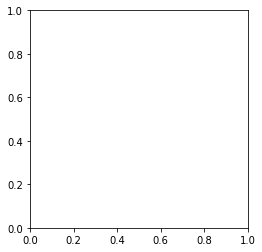

In [27]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

# Assuming `dataset` is your dataset
for i in range(len(train_data)):
    # Get the image and its label
    image, label = train_data[i]['image'],train_data[i]['class']

    # Convert the tensor image to numpy for visualization
    
    #image = image.numpy().transpose((1, 2, 0))
    #print(image)
    # Display the image
    plt.imshow(image)
    plt.title(f'Image {i}, Label: {label}')
    plt.show()

    # Ask the user if they want to remove the image from the dataset
    remove = input("Do you want to remove this image from the dataset? (yes/no): ")

    if remove.lower() == 'yes':
        # Remove the image from the dataset
        del train_data[i]
        
    # Clear the output to make the notebook cleaner
    clear_output(wait=True)

In [29]:
class MouseSuturesDataset(Dataset):
    def __init__(self, data, augment=False):
        self.data = data
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]['image']
        min_im = image.min()
        max_im = image.max()
        image = (image - min_im) / (max_im - min_im)
        image = torch.tensor(image, dtype=torch.float32)

        image = image.unsqueeze(0)  # Add channel dimension
        if self.augment and random.random() > 0.5:
            image = self._augment_image(image)

        label = self.data[idx]['class']
        label = self._convert_class_to_int(label)
        return image, label

    def _convert_class_to_int(self, class_value):
        return torch.tensor(int(class_value), dtype=torch.long)

    def _augment_image(self, image):
        # Randomly choose which augmentation to apply
        if random.random() > 0.2:
            image = self._random_shift(image)
        if random.random() > 0.2:
            image = self._add_gaussian_noise(image)
        return image

    def _random_shift(self, image, max_shift=5):
        # Randomly shift the image along each axis
        shift_h, shift_w = np.random.randint(-max_shift, max_shift+1, size=2)
        image = torch.roll(image, shifts=(shift_h, shift_w), dims=(1, 2))
        return image

    def _add_gaussian_noise(self, image, mean=0, std=0.1):
        noise = torch.randn(image.size()) * std + mean
        image = image + noise
        image = torch.clamp(image, 0, 1)  # Ensure values are within [0, 1]
        return image

In [30]:

save_folder = r'/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_data_sutures'#,process_image

In [ ]:
test_df.to_csv("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/test_data_sutures/test_names.csv")

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from PIL import ImageOps

# Transform to convert single-channel image to three-channel image
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])
# Extract features using modified ResNet
def extract_features(model, images_2d):
    model.eval()
    features = []
    with torch.no_grad():
        for image_2d in images_2d:
            image_2d = transform(image_2d).unsqueeze(0).float().to(device)  # Add batch and channel dimensions
            feature = model(image_2d)
            feature = torch.flatten(feature, 1)  # Flatten the output
            features.append(feature)
    return torch.stack(features)



vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT).to(device)
#print(vgg.classifier)
# for param in vgg.parameters():
#    param.requires_grad = False
    
#Replace the classifier part with a custom one
vgg.classifier[6] = nn.Linear(4096, 1).to(device)

# resnet50 = models.resnet50(pretrained=True).to(device)
# for param in resnet50.parameters():
#     param.requires_grad = False

# Replace the final layer with a custom one
# num_ftrs = resnet50.fc.in_features
# resnet50.fc = nn.Linear(num_ftrs, 1).to(device)  # Assuming you're doing a regression task

In [5]:
from matplotlib.pyplot import imsave
num_epochs = 500
class InvertGrayscalePIL:
    def __call__(self, image):
        return ImageOps.invert(image)
    
    
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Lambda(InvertGrayscalePIL()),  # Invert grayscale image
    transforms.Lambda(lambda x: x.crop((60, 100, x.width-60, x.height-120))),
    
    #transforms.Resize((224, 224)),  # Resize images to fit VGG16 input
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize according to VGG16 training data
])
#%

# save images to folder after processing
# for i in range(len(test_data)):
#     image = test_data[i]['image']
#     image = transform(image)
#     image = image.permute(1, 2, 0).numpy()
#     has_sutures = test_data[i]['class']
#     imsave(os.path.join(save_folder, f'{i}_{has_sutures}.png'), image)
    
best_val_loss = 1000

train_dataset = MouseSuturesDataset(train_data, True)
test_dataset = MouseSuturesDataset(test_data, False)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=1, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

criterion = nn.L1Loss()
#vgg = resnet50
optimizer = torch.optim.Adam(vgg.parameters(), lr=1e-5)

early_stopping_patience = 15

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.92)
epoch_losses = []
val_losses = []
for epoch in range(500):
    vgg.train()
    running_loss = 0.0
    for inputs, labels in tqdm(train_loader):
        
        inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
        
        optimizer.zero_grad()
        outputs = vgg(inputs.unsqueeze(0))
        #print(outputs)
        #print(outputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    epoch_loss = running_loss / len(train_loader.dataset)
    vgg.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
            outputs = vgg(inputs.unsqueeze(0))
            loss = criterion(outputs, labels)
            val_loss += loss.item() #* inputs.size(0)
    
    val_loss = val_loss / len(test_loader.dataset)
    val_losses.append(val_loss)
    scheduler.step(val_loss)
    
    print(f'Epoch {epoch+1}/{num_epochs}, Training Loss: {epoch_loss:.4f}, Validation Loss: {val_loss:.4f}')
    epoch_losses.append(epoch_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(vgg.state_dict(), '/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/best_orientation_classifier.pth')
    else:
        patience_counter += 1
        if patience_counter >= early_stopping_patience:
            print("Early stopping triggered")
            break  

NameError: name 'MouseSuturesDataset' is not defined

  0%|          | 0/200 [00:00<?, ?it/s]

failed for  38 Ground Truth  tensor(1., device='cuda:0') Pred  tensor([[False]], device='cuda:0')


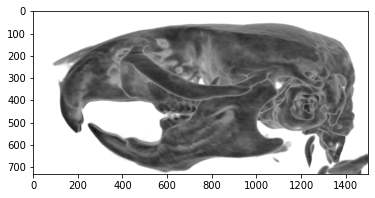

failed for  50 Ground Truth  tensor(1., device='cuda:0') Pred  tensor([[False]], device='cuda:0')


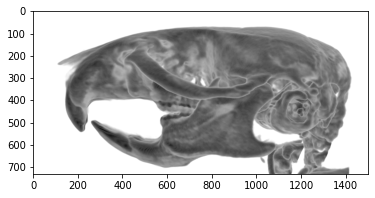

Accuracy: 0.9900, Precision: 1.0000, Recall: 0.9826, F1 Score: 0.9912


In [92]:
true_positives = 0
true_negatives = 0
false_positives = 0
false_negatives = 0
# load the best model
#vgg.load_state_dict(torch.load('best_model.pth'))
for i in tqdm(range(len(test_dataset))):
    inputs, labels = test_dataset[i]
    inputs, labels = transform(inputs.squeeze(0).float()).to(device), labels.float().to(device)
    outputs = vgg(inputs.unsqueeze(0))
    predicted_class = outputs > 0.5
    true_class = labels
    if true_class != predicted_class:
        print("failed for ", i, "Ground Truth ",true_class,"Pred ",predicted_class)
        plt.imshow(inputs.cpu().numpy()[0], cmap='gray')
        plt.show()
    if true_class == 1 and predicted_class == 1:
        true_positives += 1
    elif true_class == 0 and predicted_class == 0:
        true_negatives += 1
    elif true_class == 0 and predicted_class == 1:
        false_positives += 1
    elif true_class == 1 and predicted_class == 0:
        false_negatives += 1

accuracy = (true_positives + true_negatives) / (true_positives + true_negatives + false_positives + false_negatives)
precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)
f1_score = 2 * precision * recall / (precision + recall)
print(f'Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1_score:.4f}')
        #print(outputs.argmax(0))

In [ ]:
print(val_loss,epoch_loss,epoch)

In [ ]:
best_val_loss

In [ ]:
os.path.exists(r"/home/varhai/PRIMUS/var_vestlontest/export/images")

In [ ]:
from torchvision.transforms import Invert


In [ ]:
test_data[0]

In [61]:
train_dataset = MouseSuturesDataset(train_data, True)
test_dataset = MouseSuturesDataset(test_data, False)


In [59]:
test_dataset[0]

ValueError: invalid literal for int() with base 10: 'False'

In [90]:
torch.save(vgg.state_dict(), '/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/models/best_orientation_classifier.pth')

In [7]:
vgg.load_state_dict(torch.load('/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/models/best_orientation_classifier.pth'))

<All keys matched successfully>

In [21]:
# use model for generating labels
vgg.eval()
#read image one by one from top_df
top_df['predicted_class'] = None
for i in tqdm(range(len(top_df))):
    subj = dict(top_df.iloc[i])
    image_path = images_folder + subj['VALUE_IMAGE_URI']
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    image = torch.tensor(image, dtype=torch.float32)
    image = image.unsqueeze(0)  # Add channel dimension
    image = transform(image.squeeze(0).float()).to(device)
    outputs = vgg(image.unsqueeze(0))
    predicted_class = outputs > 0.5
    top_df.loc[i, 'predicted_class'] = predicted_class.detach().cpu().numpy()[0][0]
    
    if (~ predicted_class.detach().cpu().numpy()[0][0]):
        print(predicted_class.detach().cpu().numpy()[0][0])
    
    #print(outputs.argmax(0))




  0%|          | 0/10342 [00:00<?, ?it/s]

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
Fals

In [23]:
top_df = top_df[top_df['predicted_class'] == False]

top_df.to_csv("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/results/top_wrong_names.csv")